# 3. Sentiment Classification

## Objective
Build a baseline sentiment classifier to predict whether a movie review expresses positive or negative sentiment.

## Approach
- TF-IDF for text feature extraction
- Logistic Regression for classification
- Stratified train-test split
- Evaluation using accuracy, precision, recall, F1-score and a confusion matrix

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [5]:
# Loading the proecessed dataset
data_path = Path("../dataset/processed/imdb_reviews_cleaned.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print(df.head(3))
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Dataset shape: (49582, 3)
                                              review sentiment  \
0  One of the other reviewers has mentioned that ...  positive   
1  A wonderful little production. <br /><br />The...  positive   
2  I thought this was a wonderful way to spend ti...  positive   

                                      cleaned_review  
0  one of the other reviewers has mentioned that ...  
1  a wonderful little production. the filming tec...  
2  i thought this was a wonderful way to spend ti...  

Sentiment distribution:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


In [6]:
# Confirming the features present in the dataset
X = df["cleaned_review"]
y = df["sentiment"]

print("Features:", X.shape)
print("Labels:", y.shape)

Features: (49582,)
Labels: (49582,)


In [7]:
# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 39665
Testing samples: 9917


In [8]:
# Convert reviews into TF-IDF features
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

Training matrix shape: (39665, 50000)
Testing matrix shape: (9917, 50000)


In [9]:
# Training the baseline model
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Model training complete.")

Model training complete.


In [10]:
# Evaluating the model
y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Test Accuracy: 0.9079

Classification Report:

              precision    recall  f1-score   support

    negative       0.92      0.89      0.91      4940
    positive       0.90      0.92      0.91      4977

    accuracy                           0.91      9917
   macro avg       0.91      0.91      0.91      9917
weighted avg       0.91      0.91      0.91      9917



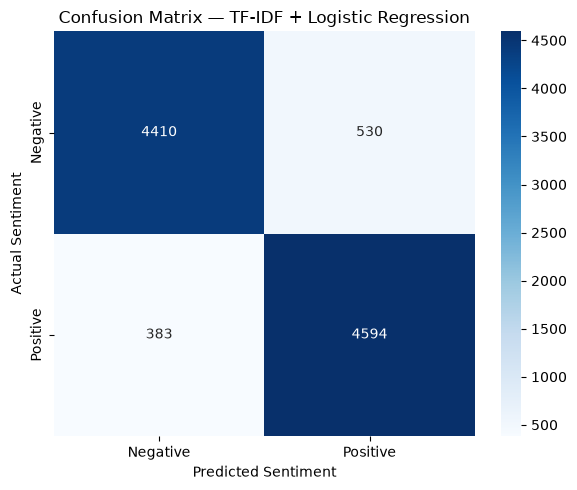

In [11]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["negative", "positive"]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Confusion Matrix — TF-IDF + Logistic Regression")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()

In [12]:
# Saving the model metrics
from pathlib import Path
import json

results = {
    "model": "TF-IDF + Logistic Regression",
    "test_accuracy": round(accuracy, 4),
    "negative_precision": 0.92,
    "negative_recall": 0.89,
    "negative_f1": 0.91,
    "positive_precision": 0.90,
    "positive_recall": 0.92,
    "positive_f1": 0.91,
}

results_path = Path("../dataset/processed/baseline_results.json")
results_path.parent.mkdir(parents=True, exist_ok=True)

with open(results_path, "w", encoding="utf-8") as file:
    json.dump(results, file, indent=4)

print(f"Results saved to {results_path}")

Results saved to ..\dataset\processed\baseline_results.json


In [13]:

import joblib

# We'll save the model artifacts in the project root.
project_dir = Path.cwd().parent
model_dir = project_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Replace these two variable names if your notebook uses different ones.
joblib.dump(tfidf, model_dir / "tfidf_vectorizer.pkl")
joblib.dump(model, model_dir / "sentiment_model.pkl")

print("Model artifacts saved successfully.")


Model artifacts saved successfully.
